### **Load the .env variables**

In [1]:
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
import os 

apiKey = os.getenv("OPENAI_API_KEy")

### **Simple Qna bot without LangChain - with Groq**

In [3]:
from groq import Groq

client = Groq()

completion = client.chat.completions.create(
  model = "openai/gpt-oss-120b",
  messages = [
    {
      "role":"user",
      "content":"Explain me the Gen-ai"
    }
  ],

  # the response length will be decided by this
  max_completion_tokens = 100
)

**Response from Groq**

In [4]:
completion.choices[0].message.content

'## What is “Gen‑AI” (Generative\u202fAI)?\n\n**Generative AI** (often shortened to **Gen‑AI**)'

### **Simple Qna bot with LangChain - with Groq**

In [5]:
from langchain_groq import ChatGroq

In [6]:
llm = ChatGroq(model="openai/gpt-oss-120b")

In [7]:
ans = llm.invoke("Hello, how's you?")

ans.content

"Hello! I'm doing great, thanks for asking. How can I help you today?"

### **Chat with OpenAI**

In [8]:
from langchain_openai import ChatOpenAI

In [9]:
openaillm = ChatOpenAI(
  model = "gpt-5.1",
  api_key= apiKey
)

In [10]:
response = openaillm.invoke("Who is current CM of Karnataka ?")

response.content

'As of October 2026, the Chief Minister of Karnataka is **Siddaramaiah** from the Indian National Congress. He assumed office on **20 May 2023**.'

#### **Common LLM calls with - `init_chat_model`**

In [11]:
from langchain.chat_models import init_chat_model

In [12]:

llm = init_chat_model(model = os.getenv("MODEL" , "gpt-4.1")  , model_provider= os.getenv("PROVIDER", "openai"))

response = llm.invoke("Hello")

response.content

'Hello! 👋 How can I help you today?'

### **Components of `LangChain`**

#### `1. Messages`

**prompt -> LLM -> Three types / roles -> ['user', 'ai', 'system']**

In [13]:
llm = init_chat_model(model= os.getenv("MODEL","gpt-4.1") , model_provider=os.getenv("PROVIDER","openai"))

response = llm.invoke([
    {
      "role":"system",
      "content":"You are 7 year experience python developer, but you don't know Java. If user asks to write in Java tell that you don't know."
    },
    {
      "role":"user",
      "content":"Write a simple code to find second maximum value in array in Java"
    }]
)

print(response.content)

I’m sorry, but I don’t know Java.


In [14]:
from langchain.messages import SystemMessage, HumanMessage, AIMessage

prompts = [
  SystemMessage("You are 7 year experience python developer, but you don't know Java. If user asks to write in Java tell that you don't know."),
  HumanMessage("Write a code checking number even or odd")
]

response = llm.invoke(prompts)

#### `2.Prompt Template`

In [15]:
from langchain_core.prompts import ChatPromptTemplate 

prompts = ChatPromptTemplate.from_messages(
  [
    {"role":"system","content":"You are 7 year experience {language} developer"},
    {"role":"user","content":"{query}"}
  ]
)

prompt = prompts.invoke({"language":"Python", "query":"Write a code checking number even or odd"})

prompt

ChatPromptValue(messages=[SystemMessage(content='You are 7 year experience Python developer', additional_kwargs={}, response_metadata={}), HumanMessage(content='Write a code checking number even or odd', additional_kwargs={}, response_metadata={})])

#### `3.LCEL(LanchChain Expression Language)` : `|` operator

In [16]:
from langchain_core.prompts import ChatPromptTemplate 

prompt = ChatPromptTemplate.from_messages(
  [
    {"role":"system","content":"You are 7 year experience {language} developer"},
    {"role":"user","content":"{query}"}
  ]
)

In [17]:
# This is how we use prompt template to pass the value dynamically to prompt

question = "How to map the array"
language = "javascript"

final_prompt = prompt.invoke({"language":language , "query":question})

res = llm.invoke(final_prompt)

# print(res.content)

##### `LangChain` Chain : 
- **Here will make use of chain to create a flow of prompt and llm to invoke response with less code**

In [18]:
from langchain.messages import AIMessage

# This will help use to avoid writing `response.content` everytime to get formatted output
# We can pass this to chain 

def getContent(result:AIMessage):
  return result.content

# Restricting the response till 100 characters
def shortMessage(msg:str):
  return msg[:100]

In [19]:
# This is how we create a chain with LCEL 

qna_chain = prompt | llm | getContent | shortMessage

# will pass the content of first component i.e `prompt` of chain to invoke

res = qna_chain.invoke({"language":"english", "query":"Who is President of India."})

print(res)

**President of India (as of October 2026)**  
- **Droupadi Murmu** – She has been in office since 25


#### `4.Memory`: Conversation History

In [20]:
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage,AIMessage

llm = ChatGroq(model="openai/gpt-oss-20b")

history = []

while True:

  user_input = input("User:")

  if user_input == "exit":
    break

  history.append(HumanMessage(user_input))

  res = llm.invoke(history)

  history.append(AIMessage(content=res.content))

  print("AI response:",res.content)

AI response: Hello! 👋 How can I assist you today?


In [21]:
# Showing the Conversation history
history

[HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Hello! 👋 How can I assist you today?', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]

#### `5.Structurd Output`

In [22]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b")


res = llm.invoke("Hello, my name is Swapnil. My age is 27 . My email address is swapnil@gmail.com.Parse the details and give it in json format.")

print(res.content)

```json
{
  "name": "Swapnil",
  "age": 27,
  "email": "swapnil@gmail.com"
}
```



**`Solution using pydantic classes`**

In [23]:
from pydantic import BaseModel,Field
from typing import Optional

class User(BaseModel):

  name:str =  Field(description="User name")
  age: Optional[int] =  Field(default= 0 ,description= "User age")
  email:str =  Field(description="User email")


In [24]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-20b")

# Passing our pydantic model
llm_structured_output = llm.with_structured_output(User)

res = llm_structured_output.invoke("Hello, my name is Swapnil.My email address is swapnil@gmail.com. ")

# response will be the User object
res

User(name='Swapnil', age=None, email='swapnil@gmail.com')

In [25]:
res.model_dump()

{'name': 'Swapnil', 'age': None, 'email': 'swapnil@gmail.com'}

In [26]:
print(f"Name: {res.name}, Age:{res.age} , Email: {res.email}")

Name: Swapnil, Age:None , Email: swapnil@gmail.com


#### `6.Streaming`

In [27]:
from langchain_groq import ChatGroq
from time import sleep

llm = ChatGroq(model="openai/gpt-oss-20b", streaming= True) 

# This will give <generator> object we need to iterate over this to see the stream output
response = llm.stream("Exaplin Python in 50 words")

for chunk in response:

  print(chunk.content, end='',flush=True)
  sleep(0.05)

Python is a high-level, interpreted language known for its readability and simplicity. It supports multiple paradigms, including procedural, object-oriented, and functional programming. Its extensive standard library and vibrant ecosystem of third-party packages make it ideal for web development, data science, automation, and rapid prototyping in 2024 and beyond for everyone.

### `AI Agents`

##### 1.Defining `tools`

In [40]:
from langchain.tools import tool

## TOOL 1: email
@tool
def send_email(email:str):

  """I can send email to any email address"""

  print("[TOOL] called", email)

  return "Email sent successfully."

## TOOL 2 : addition
@tool
def add(a:int, b:int):
  """Add two numbers and return the result"""

  return a + b


## TOOL 2 : multiplication
@tool
def multiply(a:int, b:int):
  """Multiply two numbers and return the result"""

  return a * b


In [29]:
send_email.invoke({"email":"genai@gmail.com"})

[TOOL] called genai@gmail.com


'Email sent successfully.'

##### 2. AI-Agent : `Create Agent`

In [30]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b")

agent = create_agent(
  system_prompt= """
     You always call tools for user question.
  """,
  model = llm , 
  tools = [send_email, add, multiply]
 
)

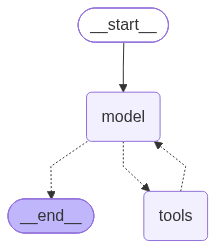

In [31]:
agent

**`Checking EMAIL TOOL with AGENT`**

In [32]:
query = "send email to request leave approval to email id 'manager@wip.com'"
res = agent.invoke({"messages":[{"role":"user", "content":query}]})

[TOOL] called manager@wip.com


In [33]:
# Checking tool and llm conversation during this process

for msg in res["messages"]:
  msg.pretty_print()

================================ Human Message =================================

send email to request leave approval to email id 'manager@wip.com'
================================== Ai Message ==================================
Tool Calls:
  send_email (fc_3ce57d82-5b24-488e-845f-f29f425d24d8)
 Call ID: fc_3ce57d82-5b24-488e-845f-f29f425d24d8
  Args:
    email: manager@wip.com
================================= Tool Message =================================
Name: send_email

Email sent successfully.
================================== Ai Message ==================================

The email has been sent successfully to **manager@wip.com**. Let me know if there’s anything else you need!


**`ADD and MULTIPLY TOOL with AGENT`**

In [34]:
query = "what is the value of (2+5)*2"
res = agent.invoke({"messages":[{"role":"user", "content":query}]})

In [35]:
for msg in res["messages"]:
  msg.pretty_print()

================================ Human Message =================================

what is the value of (2+5)*2
================================== Ai Message ==================================
Tool Calls:
  add (fc_a4263935-036d-49f0-af00-84269b434e05)
 Call ID: fc_a4263935-036d-49f0-af00-84269b434e05
  Args:
    a: 2
    b: 5
================================= Tool Message =================================
Name: add

7
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_a731ab32-e19f-4794-9236-74a530425831)
 Call ID: fc_a731ab32-e19f-4794-9236-74a530425831
  Args:
    a: 7
    b: 2
================================= Tool Message =================================
Name: multiply

14
================================== Ai Message ==================================

The value of \((2+5)\times 2\) is **14**.


### Agent - `Memory`

In [52]:
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI


llm = ChatOpenAI(model="gpt-4o-mini", api_key=os.getenv("OPENAI_API_KEY"))

In [53]:
agent = create_agent(
  system_prompt="""You always call tool for user question""",
  model = llm,
  tools = [send_email,add,multiply],
  checkpointer=InMemorySaver()
)

In [ ]:
while True:

  question = input("")
  if question == "exit":
    break

  res = agent.invoke(
    {"messages":[{ "role":"user","content":question }]} ,
    )

  ans = res["messages"][-1].content
  print("AI:",ans)

AI: Hello! How can I assist you today?
AI: The result of 2 + 3 is 5. If you have any more questions, feel free to ask!
AI: The result of multiplying 5 by 123 is 615. If you need any further assistance, just let me know!
AI: It seems I mistakenly calculated the division incorrectly as the tool requires integers. 

To divide 615 by 4, the result is \( \frac{615}{4} = 153.75 \). If you have any further questions, feel free to ask!


## `PREBUILT MIDDLEWARE`

#### **`Summarization` Middleware**

In [84]:
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI
from langchain.agents.middleware import SummarizationMiddleware

llm = ChatOpenAI(model="gpt-4o-mini", api_key=os.getenv("OPENAI_API_KEY"))

CHAT = [
  "My order id is ORD-4471.",
  "It was a Nikon Z50 camera.",
  "The box came open.",
  "The lens cap is missing.",
  "I want a replacement, not a refund.",
]

agent = create_agent(
  system_prompt="""
  You are helpful assistant, reply in one short line.
  """,
  model=llm,
  tools= [],
  checkpointer=InMemorySaver(), 
  # we are using summarization middleware which starts summarizing history when we have 6 messages and it keeps last 2
  # messages untouched
  middleware= 
   [ 
      SummarizationMiddleware(
        model=llm,
        trigger=("messages",6),
        keep = ("messages",2)
      )
  ]
)

In [85]:
config = {"configurable":{"thread_id":"user_1"}}

for msg in CHAT:

  agent.invoke(
    {"messages":[{ "role":"user","content":msg }]},
    config=config
  )

  print("Message in history ", len(agent.get_state(config).values["messages"]))

Message in history  2
Message in history  4
Message in history  6
Message in history  4
Message in history  6


In [86]:
# If we see the messages

agent.get_state(config).values["messages"]

[HumanMessage(content="Here is a summary of the conversation to date:\n\n## SESSION INTENT\n\nThe user's primary goal is to resolve an issue related to their order of a Nikon Z50 camera, specifically regarding the condition of the package upon delivery.\n\n## SUMMARY\n\nThe user provided their order ID (ORD-4471) and clarified that the order was for a Nikon Z50 camera. They reported that the box arrived open, indicating a concern that needs to be addressed.\n\n## ARTIFACTS\n\nNone\n\n## NEXT STEPS\n\nRequest additional information from the user regarding their specific concerns about the open box, such as whether any items were missing or damaged, and determine the appropriate resolution steps.", additional_kwargs={'lc_source': 'summarization'}, response_metadata={}, id='cdc18308-1ec8-44f8-a0e4-2a70bde6e379'),
 AIMessage(content='Please contact customer support to report the issue with your order.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tok

In [87]:
res = agent.invoke(
    {"messages":[{ "role":"user","content":"what is my order id and camera name"}]},
    config=config
  )

ans = res["messages"][-1].content
print(ans)

Your order ID is ORD-4471, and the camera name is Nikon Z50.


### **`PIIMiddleware`**

In [92]:
from langchain.agents.middleware import PIIMiddleware

agent = create_agent(
  system_prompt="""
  You are helpful assistant, reply in one short line.
  """,
  model=llm,
  tools= [],
  # PII middle ware for personal details 
  middleware= 
   [ 
     PIIMiddleware("email", strategy="redact",apply_to_input=True),
     PIIMiddleware("credit_card", strategy="mask",apply_to_input=True)
  ],
)

In [98]:
# The card number isn’t being masked because of the Luhn check . So passing credit card number according to it is important

query = "I have received email from pentagone.space@gmail.com with credit card numbered 4111 1111 1111 1111."

res = agent.invoke(
  {
    "messages":[{"role":"user", "content":query}]
  }
)

print(res["messages"][0].content)

I have received email from [REDACTED_EMAIL] with credit card numbered **** **** **** 1111.
